# Часть 2. Затраты на финансирование оборотного капитала и валютные курсы

**Задача:** разложить надбавку на компоненты; взять **затраты на оборотный капитал** — сколько денег «заморожено», пока товар производится, хранится, плывёт и ждёт оплаты, и сколько стоит кредит на это время (с учётом дорогих кредитов в некоторых странах). Дополнительно — влияние **валютных курсов**.

затраты на тонну = цена тонны × дни цикла × ставка / 365

затраты в год = стоимость груза × число судов в год × дни × ставка / 365

**Данные:**
- дни цикла — квартальная отчётность SEC (EDGAR) трёх производителей азотных удобрений США: CF Industries, CVR Partners, LSB Industries (src/data/load_edgar.py);
- ставки и курсы — FRED (src/data/load_fred.py);
- цена карбамида — Pink Sheet.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

wc = pd.read_csv("../data/processed/working_capital_quarterly.csv", parse_dates=["quarter_end"])
fred = pd.read_csv("../data/processed/fred_monthly.csv", index_col="date", parse_dates=True)
prices = pd.read_parquet("../data/processed/prices_monthly.parquet").loc["2015-04":]
print("Оборотный капитал:", len(wc), "компания-кварталов,", wc["quarter_end"].min().date(), "–", wc["quarter_end"].max().date())
print("FRED:", fred.index.min().date(), "–", fred.index.max().date(), list(fred.columns))

Оборотный капитал: 153 компания-кварталов, 2014-03-31 – 2026-09-30
FRED: 2010-01-01 – 2026-11-01 ['fed_rate', 'sofr', 'spread_us_bbb', 'spread_em_corp', 'usd_index', 'inr_per_usd', 'brl_per_usd']


## 1. Дни цикла по отчётности производителей

- **DSO** — дни до оплаты покупателем = дебиторская задолженность / выручка за квартал × 91;
- **DIO** — дни хранения запасов = запасы / себестоимость за квартал × 91;
- **DPO** — дни отсрочки поставщикам (в т. ч. за газ) = кредиторская задолженность / себестоимость × 91;
- **DSO + DIO** — сколько дней деньги вложены в товар («валовой» цикл), **DSO + DIO − DPO** — сколько из них производитель финансирует сам.

Медианы по кварталам 2014–2026, дней:
                 DSO   DIO   DPO  DSO + DIO  цикл (− DPO)
company                                                  
CF Industries   23.6  32.3  52.7       57.3           6.7
CVR Partners    25.2  64.6  27.4       86.1          55.3
LSB Industries  42.8  19.3  50.0       61.8          11.8

Пропуски по колонкам, %:
revenue        8.5
cogs           3.3
receivables    0.0
inventory      0.7
payables       9.8


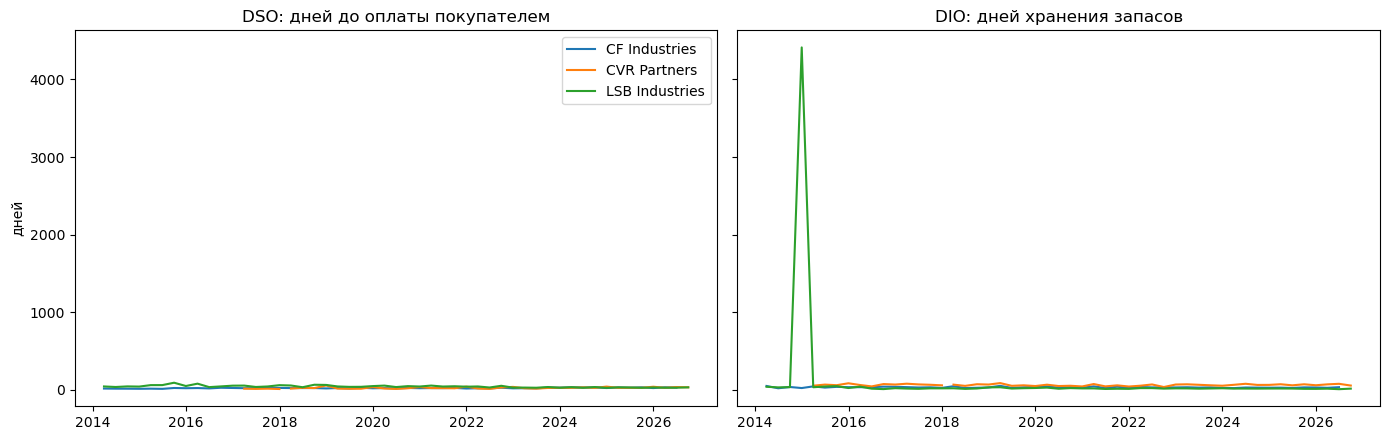

In [2]:
wc["gross_days"] = wc["dso_days"] + wc["dio_days"]
summary = wc.groupby("company")[["dso_days", "dio_days", "dpo_days", "gross_days", "cycle_days"]].median().round(1)
summary.columns = ["DSO", "DIO", "DPO", "DSO + DIO", "цикл (− DPO)"]
print("Медианы по кварталам 2014–2026, дней:")
print(summary.to_string())

print("\nПропуски по колонкам, %:")
print((wc[["revenue", "cogs", "receivables", "inventory", "payables"]].isna().mean() * 100).round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for company, part in wc.groupby("company"):
    part = part.sort_values("quarter_end")
    axes[0].plot(part["quarter_end"], part["dso_days"], label=company)
    axes[1].plot(part["quarter_end"], part["dio_days"], label=company)
axes[0].set_title("DSO: дней до оплаты покупателем")
axes[1].set_title("DIO: дней хранения запасов")
axes[0].set_ylabel("дней")
axes[0].legend()
plt.tight_layout()
plt.show()

**Вывод:**
- Деньги вложены в товар в среднем **около 60 дней** (DSO + DIO: CF Industries ≈ 59, LSB ≈ 62, CVR ≈ 85). Из них около 20–45 дней покупатели платят, 20–65 дней продукция лежит на складе — запасы копят к сезону внесения.
- **DPO у CF Industries завышен:** компания отчитывается в основном строкой «кредиторская задолженность **и начисленные обязательства**», поэтому «цикл − DPO» у неё почти ноль. Для расчёта затрат берём **DSO + DIO** — именно эти дни деньги заморожены в товаре.
- Это американские производители, которые продают в основном внутри страны. **У экспортёров Ближнего Востока к циклу добавляется морской рейс** (≈ 10 дней до Индии, ≈ 30 до Бразилии — уточняем по PortWatch у Саши).
- Отдельно у CF Industries в отчётности есть строка «задолженность за покупку газа» — газ оплачивается с отсрочкой, это снижает потребность в оборотном капитале.

## 2. Ставка по кредиту
Ставка ФРС — база для долларовых кредитов. Спреды корпоративных облигаций показывают, сколько сверху платит компания: FRED отдаёт их только за последние 3 года (ограничение лицензии ICE), поэтому используем их, чтобы обосновать надбавку банка, а не как ряд с 2015 года.

In [3]:
print("Спреды с ноября 2023, медиана, п.п.:")
print(fred[["spread_us_bbb", "spread_em_corp"]].dropna().median().round(2).to_string())

BANK_SPREAD = 2.0
fred["financing_rate"] = fred["fed_rate"] + BANK_SPREAD
print(f"\nСтавка = ставка ФРС + {BANK_SPREAD} п.п. Средняя по годам, %:")
print(fred["financing_rate"].loc["2015":].groupby(fred.loc["2015":].index.year).mean().round(2).to_string())

Спреды с ноября 2023, медиана, п.п.:
spread_us_bbb     1.07
spread_em_corp    1.69

Ставка = ставка ФРС + 2.0 п.п. Средняя по годам, %:
date
2015    2.13
2016    2.40
2017    3.00
2018    3.83
2019    4.16
2020    2.38
2021    2.08
2022    3.68
2023    7.02
2024    7.14
2025    6.21
2026    5.67


**Вывод:** компании рейтинга BBB в США платят сверху ≈ 1 п.п., компании развивающихся стран ≈ 1,5 п.п. (по облигациям; банковский кредит обычно дороже). Берём **надбавку 2 п.п.** к ставке ФРС. Ставка за 2015–2026 менялась от ≈ 2% (2015, 2020–2021) до ≈ 7% (2023–2024) — это главный источник изменения затрат во времени.

## 3. Затраты на финансирование, \$ на тонну, по месяцам

Дни цикла: 62 (DSO + DIO, медиана по компаниям) + 10 (рейс до Индии) = 72
count    138.0
mean       3.0
std        2.0
min        0.7
25%        1.2
50%        2.1
75%        4.7
max        9.5

Доля в надбавке (k = 12), медиана: 1.0 %
Затраты по годам, $/т:
date
2015    1.1
2016    0.9
2017    1.3
2018    1.9
2019    2.0
2020    1.1
2021    2.0
2022    4.8
2023    4.9
2024    4.7
2025    5.2
2026    6.0

Затраты в год (2026-09): груз 40,000 т × 50 судов × 72 дн. × 5.75% = $9.2 млн в год


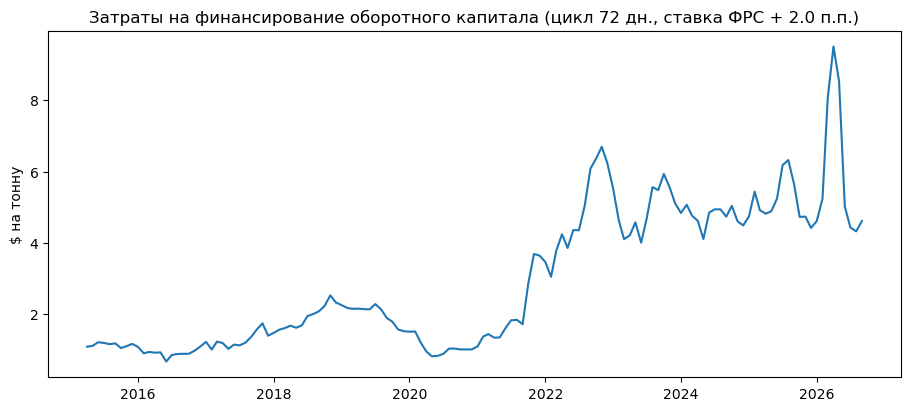

In [4]:
gross_days = wc.groupby("company")["gross_days"].median().median()
VOYAGE_DAYS = 10
cycle_days = gross_days + VOYAGE_DAYS
print(f"Дни цикла: {gross_days:.0f} (DSO + DIO, медиана по компаниям) + {VOYAGE_DAYS} (рейс до Индии) = {cycle_days:.0f}")

df = prices.join(fred[["financing_rate"]])
df["financing_cost_usd_t"] = df["urea_price"] * cycle_days * df["financing_rate"] / 100 / 365
df["markup_k12"] = df["urea_price"] - 12 * df["gas_europe"]
df["share_of_markup_%"] = df["financing_cost_usd_t"] / df["markup_k12"] * 100

print(df["financing_cost_usd_t"].describe().round(1).to_string())
print("\nДоля в надбавке (k = 12), медиана:", round(df["share_of_markup_%"].median(), 1), "%")
print("Затраты по годам, $/т:")
print(df["financing_cost_usd_t"].groupby(df.index.year).mean().round(1).to_string())

latest = df.dropna().iloc[-1]
cargo_tonnes, ships_per_year = 40000, 50
annual = latest["urea_price"] * cargo_tonnes * ships_per_year * cycle_days * latest["financing_rate"] / 100 / 365
print(f"\nЗатраты в год ({latest.name:%Y-%m}): груз {cargo_tonnes:,} т × {ships_per_year} судов × {cycle_days:.0f} дн. × {latest['financing_rate']:.2f}% = ${annual / 1e6:.1f} млн в год")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(df.index, df["financing_cost_usd_t"])
ax.set_ylabel("$ на тонну")
ax.set_title(f"Затраты на финансирование оборотного капитала (цикл {cycle_days:.0f} дн., ставка ФРС + {BANK_SPREAD} п.п.)")
plt.show()

**Вывод:** при цикле ≈ 70 дней затраты на финансирование составляют **несколько долларов на тонну** (порядка \$2–3 в 2015–2021, около \$6–8 в 2022–2024 из-за высоких цен и ставок) — **несколько процентов надбавки**. Компонента небольшая, но меняется по понятным причинам: ставки ФРС, цена груза, длина рейса (обход Красного моря, перекрытие Ормуза). Как признак — financing_cost_usd_t; при ставке 20% (страны с дорогими кредитами) и 120 днях затраты были бы в 4–8 раз выше.

In [5]:
price_now = latest["urea_price"]
sens = pd.DataFrame(
    {f"ставка {r}%": [round(price_now * d * r / 100 / 365, 1) for d in [60, 90, 120]] for r in [5, 8, 20]},
    index=["60 дней", "90 дней", "120 дней"],
)
print(f"Чувствительность при цене ${price_now:.0f}/т ({latest.name:%Y-%m}), $ на тонну:")
sens

Чувствительность при цене $408/т (2026-09), $ на тонну:


,ставка 5%,ставка 8%,ставка 20%
60 дней,3.3,5.4,13.4
90 дней,5.0,8.0,20.1
120 дней,6.7,10.7,26.8


## 3а. Дорогие кредиты в странах-производителях
В некоторых странах кредиты сильно дороже. Берём ключевые ставки центробанков (BIS, src/data/load_bis_rates.py) и считаем затраты на финансирование при местной ставке + 2 п.п. Египта в базе BIS нет.

Ключевые ставки 2015–2026, %:
     rate_india  rate_china  rate_russia  rate_saudi_arabia  rate_brazil
min        4.00        3.00         4.25               1.00         2.00
50%        6.00        3.85         9.50               2.25        11.75
max        7.75        5.60        21.00               6.00        15.00

Затраты на финансирование при местной ставке + 2 п.п., $ на тонну, средние по годам:
      cost_rate_india  cost_rate_china  cost_rate_russia  cost_rate_saudi_arabia  cost_rate_brazil  cost_usd_fed
date                                                                                                            
2015              4.8              3.6               7.2                     2.1               8.5           1.1
2016              3.2              2.4               4.8                     1.5               6.2           0.9
2017              3.4              2.7               4.6                     1.7               5.0           1.3
2018              4.1      

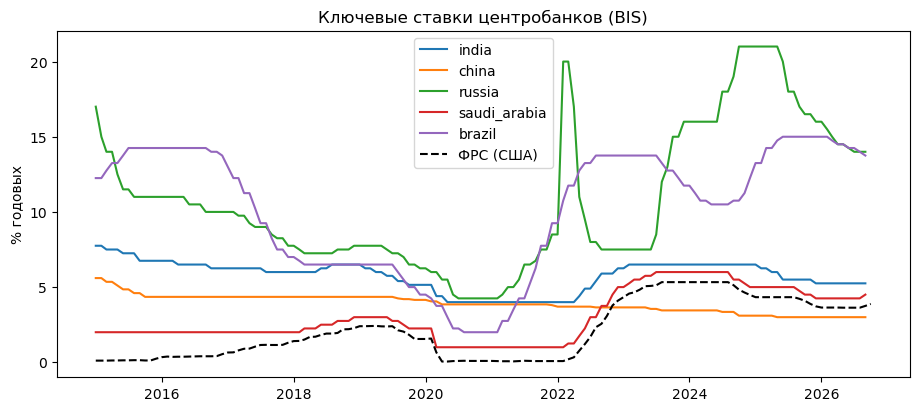

In [6]:
policy = pd.read_csv("../data/processed/policy_rates_monthly.csv", index_col="date", parse_dates=True)
print("Ключевые ставки 2015–2026, %:")
print(policy.loc["2015":].describe().loc[["min", "50%", "max"]].round(2).to_string())

local = prices[["urea_price"]].join(policy)
for col in policy.columns:
    local["cost_" + col] = local["urea_price"] * cycle_days * (local[col] + BANK_SPREAD) / 100 / 365
local["cost_usd_fed"] = df["financing_cost_usd_t"]
cost_cols = [c for c in local.columns if c.startswith("cost_")]
print("\nЗатраты на финансирование при местной ставке + 2 п.п., $ на тонну, средние по годам:")
print(local[cost_cols].groupby(local.index.year).mean().round(1).to_string())

fig, ax = plt.subplots(figsize=(11, 4.5))
for col in policy.columns:
    ax.plot(policy.loc["2015":].index, policy.loc["2015":, col], label=col.replace("rate_", ""))
ax.plot(fred.loc["2015":].index, fred.loc["2015":, "fed_rate"], color="black", linestyle="--", label="ФРС (США)")
ax.set_ylabel("% годовых")
ax.set_title("Ключевые ставки центробанков (BIS)")
ax.legend()
plt.show()

**Вывод:** ставка Саудовской Аравии привязана к ставке ФРС (риал привязан к доллару), поэтому затраты саудовских экспортёров — как в долларовом расчёте выше. В России ставка доходила до 21%, в Бразилии — до 15%: если производитель кредитуется в местной валюте, финансирование того же груза обходится **в несколько раз дороже** (порядка \$10–20 на тонну против \$2–6 при долларовой ставке). На мировую цену это влияет мало — её задаёт самый дорогой нужный рынку производитель, а не самый закредитованный, — но объясняет, почему у разных экспортёров разная маржа.

## 3б. Уточнения: предоплаты, сумма оборотного капитала, реальная ставка, число судов, доля в марже

Сначала чистим ошибочные значения: в отдельных кварталах выручка или себестоимость, восстановленные из нарастающего итога, получаются почти нулевыми, и дни взлетают до тысяч; процентная ставка по долгу бывает отрицательной (возврат процентов) или бесконечной (долг погашен). Такие значения считаем ошибками и убираем.

In [7]:
clean = wc.copy()
bad = pd.DataFrame({
    "DIO > 200 дней": clean["dio_days"] > 200,
    "DPO > 200 дней": clean["dpo_days"] > 200,
    "ставка по долгу вне 0–20%": ~clean["debt_rate_pct"].between(0, 20) & clean["debt_rate_pct"].notna(),
})
print("Найдено ошибочных значений:")
print(bad.sum().to_string())
clean.loc[bad["DIO > 200 дней"], "dio_days"] = np.nan
clean.loc[bad["DPO > 200 дней"], "dpo_days"] = np.nan
clean.loc[bad["ставка по долгу вне 0–20%"], "debt_rate_pct"] = np.nan
clean["year"] = clean["quarter_end"].dt.year

Найдено ошибочных значений:
DIO > 200 дней               1
DPO > 200 дней               1
ставка по долгу вне 0–20%    7


### Предоплата покупателей
Фермеры и дистрибьюторы часто платят вперёд — до отгрузки (в отчётности: «обязательства по договорам с покупателями», «отложенная выручка»). Пока аванс у производителя, ему нужно меньше своих денег.

In [8]:
print("Авансы покупателей, дней выручки (медиана по годам):")
print(clean.pivot_table(index="year", columns="company", values="advance_days", aggfunc="median").round(1).to_string())

clean["net_days"] = clean["dso_days"] + clean["dio_days"] - clean["advance_days"].fillna(0)
net_days = clean.groupby("company")["net_days"].median().median()
print(f"\nДни, которые производитель финансирует сам: DSO + DIO − авансы = {net_days:.0f} (медиана по компаниям; было {gross_days:.0f} без учёта авансов)")

Авансы покупателей, дней выручки (медиана по годам):
company  CF Industries  CVR Partners  LSB Industries
year                                                
2017               NaN          15.0             8.5
2018               NaN          31.8             6.4
2019              10.3          23.2             4.5
2020              13.0          22.1             2.6
2021              25.1          31.6             1.0
2022              13.5          26.7             0.7
2023              10.2          14.1             0.6
2024               6.7          21.4             0.7
2025               8.5          18.0             0.6
2026               3.2          14.3             0.3

Дни, которые производитель финансирует сам: DSO + DIO − авансы = 56 (медиана по компаниям; было 62 без учёта авансов)


### Сколько денег вложено в оборотный капитал
Оборотный капитал = дебиторская задолженность + запасы − кредиторская задолженность − авансы покупателей.

In [9]:
clean["annual_revenue"] = clean.groupby("company")["revenue"].transform(lambda s: s.rolling(4, min_periods=4).sum())
clean["wc_share_pct"] = clean["working_capital_usd"] / clean["annual_revenue"] * 100
table = clean.groupby("company").agg(
    оборотный_капитал_млн=("working_capital_usd", lambda s: s.median() / 1e6),
    доля_годовой_выручки_pct=("wc_share_pct", "median"),
).round(1)
print(table.to_string())

                оборотный_капитал_млн  доля_годовой_выручки_pct
company                                                        
CF Industries                    -1.0                      -0.0
CVR Partners                     30.2                       8.3
LSB Industries                   17.2                       3.4


### Реальная ставка, по которой занимают производители
Процентные расходы за квартал × 4 / долг. Сравниваем с допущением «ставка ФРС + 2 п.п.».

In [10]:
real_rate = clean.pivot_table(index="year", columns="company", values="debt_rate_pct", aggfunc="median")
real_rate["ставка ФРС + 2 п.п."] = fred["financing_rate"].groupby(fred.index.year).mean()
print("Ставка, % годовых:")
print(real_rate.loc[2015:].round(1).to_string())
REAL_RATE = clean["debt_rate_pct"].median()
print(f"\nМедиана реальной ставки по трём компаниям: {REAL_RATE:.1f}%")

Ставка, % годовых:
company  CF Industries  CVR Partners  LSB Industries  ставка ФРС + 2 п.п.
year                                                                     
2015               2.7           4.8             1.4                  2.1
2016               3.6           4.9             7.3                  2.4
2017               6.4           9.6             9.3                  3.0
2018               5.2           9.6            10.8                  3.8
2019               5.6           9.5            10.7                  4.2
2020               4.6           9.4             0.1                  2.4
2021               5.1           6.5            10.7                  2.1
2022               8.6           6.6             7.0                  3.7
2023               5.1           6.2             6.9                  7.0
2024               5.0           6.0             6.9                  7.1
2025               5.0           6.5             6.7                  6.2
2026               

### Число судов в год — из Comtrade

In [11]:
trade = pd.read_csv("../data/raw/comtrade_urea_monthly.csv", parse_dates=["date"])
CARGO_TONNES = 40000
exports = trade[(trade["flowCode"] == "X") & (trade["country"].isin(["Саудовская Аравия", "Египет", "Оман"]))]
yearly = exports.groupby(["country", exports["date"].dt.year])["tonnes"].sum().unstack(0) / 1e6
ships = (yearly * 1e6 / CARGO_TONNES).round()
print("Экспорт карбамида, млн т в год:")
print(yearly.loc[2019:2025].round(2).to_string())
print(f"\nЧисло судов в год (партия {CARGO_TONNES:,} т):")
print(ships.loc[2019:2025].to_string())

Экспорт карбамида, млн т в год:
country  Египет  Оман  Саудовская Аравия
date                                    
2019       3.79   NaN               3.87
2020       3.94   NaN               4.43
2021       3.78   NaN               3.95
2022       3.05  2.39               4.30
2023       3.29  3.25               4.16
2024       3.22  3.49               4.44
2025       3.84  0.98               4.33

Число судов в год (партия 40,000 т):
country  Египет  Оман  Саудовская Аравия
date                                    
2019       95.0   NaN               97.0
2020       99.0   NaN              111.0
2021       95.0   NaN               99.0
2022       76.0  60.0              107.0
2023       82.0  81.0              104.0
2024       80.0  87.0              111.0
2025       96.0  25.0              108.0


In [12]:
year = 2025
saudi_ships = ships.loc[year, "Саудовская Аравия"]
saudi_price = exports[(exports["country"] == "Саудовская Аравия") & (exports["date"].dt.year == year)]
saudi_price = saudi_price["primaryValue"].sum() / saudi_price["tonnes"].sum()
days = net_days + VOYAGE_DAYS
cost = saudi_price * CARGO_TONNES * saudi_ships * days * REAL_RATE / 100 / 365
print(f"Затраты в год, Саудовская Аравия, {year}:")
print(f"  стоимость груза ${saudi_price:,.0f}/т × {CARGO_TONNES:,} т = ${saudi_price * CARGO_TONNES / 1e6:.1f} млн")
print(f"  × {saudi_ships:.0f} судов × {days:.0f} дней × {REAL_RATE:.1f}% / 365")
print(f"  = ${cost / 1e6:.1f} млн в год, или ${cost / (CARGO_TONNES * saudi_ships):.1f} на тонну")

Затраты в год, Саудовская Аравия, 2025:
  стоимость груза $437/т × 40,000 т = $17.5 млн
  × 108 судов × 66 дней × 5.2% / 365
  = $17.7 млн в год, или $4.1 на тонну


### Связь с прибыльностью завода: какую долю валовой маржи съедает финансирование
Затраты на финансирование на тонну / валовая маржа на тонну = (дни × ставка / 365) / маржа в %.

Финансирование = 0.94% цены тонны

Валовая маржа, %:
company  CF Industries  CVR Partners  LSB Industries
year                                                
2015              34.4           NaN            -7.5
2016              16.2           NaN            -8.3
2017              11.7           4.7             0.7
2018              20.6           8.9             6.5
2019              22.0           9.7            -2.6
2020              18.7           2.7             0.8
2021              32.0          31.9            19.3
2022              53.5          51.3            42.6
2023              37.4          28.9            15.4
2024              33.4          22.6            10.3
2025              39.0          31.1            15.9
2026              44.5          37.5            21.1

Доля финансирования в валовой марже, %:
company  CF Industries  CVR Partners  LSB Industries
year                                                
2015               2.7           NaN             NaN
2016 

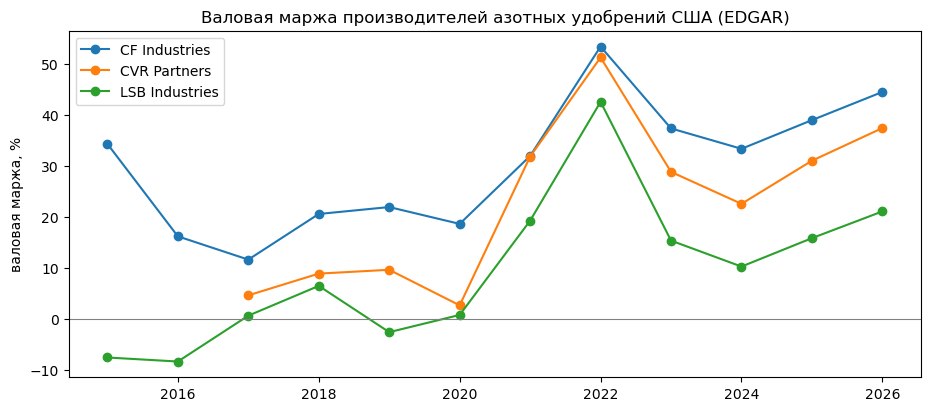

In [13]:
margin = clean.pivot_table(index="year", columns="company", values="gross_margin_pct", aggfunc="median")
financing_share_of_price = (net_days + VOYAGE_DAYS) * REAL_RATE / 365
share_of_margin = (financing_share_of_price / margin * 100).where(margin > 2)
print(f"Финансирование = {financing_share_of_price:.2f}% цены тонны")
print("\nВаловая маржа, %:")
print(margin.loc[2015:].round(1).to_string())
print("\nДоля финансирования в валовой марже, %:")
print(share_of_margin.loc[2015:].round(1).to_string())

fig, ax = plt.subplots(figsize=(11, 4.5))
for company in margin.columns:
    ax.plot(margin.loc[2015:].index, margin.loc[2015:, company], marker="o", label=company)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_ylabel("валовая маржа, %")
ax.set_title("Валовая маржа производителей азотных удобрений США (EDGAR)")
ax.legend()
plt.show()

**Выводы по уточнениям:**
- **Ошибочные значения:** 1 квартал с DIO > 200 дней, 1 с DPO > 200 и 7 кварталов с нереальной ставкой по долгу (отрицательной или бесконечной) — убраны.
- **Предоплата заметна:** авансы покупателей покрывают около 10–25 дней выручки у CF Industries и CVR Partners (у LSB — 1–2 дня); в 2021 году, в разгар дефицита, они выросли (у CF до ≈ 25 дней) — покупатели спешили закрепить объёмы. С учётом авансов производитель сам финансирует **≈ 56 дней, а не ≈ 62**.
- **Сумма оборотного капитала:** у CVR Partners ≈ \$30 млн (≈ 8% годовой выручки), у LSB ≈ \$17 млн (≈ 3%); у CF Industries — около нуля, потому что в её кредиторской задолженности учтены и начисленные обязательства, и авансы покупателей велики.
- **Реальная ставка:** производители занимают в среднем под **≈ 5–7%** (медиана 5,2%) — это облигации с фиксированной ставкой. В 2015–2021 годах это заметно выше допущения «ставка ФРС + 2 п.п.» (2–4%), а в 2023–2024 — ниже (≈ 7%). Для расчёта берём медиану реальной ставки.
- **Число судов — из данных:** Саудовская Аравия экспортирует ≈ 4,3 млн т в год ≈ **100–110 судов** по 40 тыс. т. По формуле затрат в год финансирование её экспорта в 2025 году — **≈ \$18 млн в год, ≈ \$4 на тонну**. (Данные Омана за 2025 год неполные — только до мая.)
- **Доля в марже:** финансирование — около **1% цены** тонны, но в валовой марже доля заметнее: у CF Industries 2–8%, у CVR и LSB в слабые 2017–2020 годы — **10–35%** (маржа падала до 3–10%). В 2022 году, при марже ≈ 50%, — всего ≈ 2%. Вывод: затраты на финансирование почти не двигают цену, но **сильно влияют на прибыльность заводов именно в слабые годы** — так логистика связана с прибыльностью завода.


## 4. Валютные курсы
Карбамид торгуется в долларах. Когда доллар дорожает, для фермеров Индии и Бразилии удобрения дорожают в местной валюте — спрос может снижаться.

Корреляции месячных изменений с ценой карбамида (трейн, порог ≈ ±0,2):
             тот же месяц  → цена в след. месяце
usd_index            0.15                  -0.11
inr_per_usd          0.05                  -0.05
brl_per_usd          0.05                  -0.16


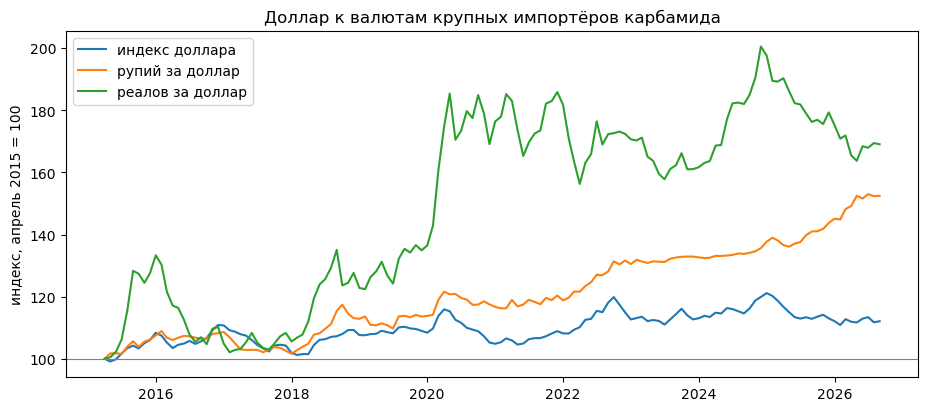

In [14]:
fx = prices[["urea_price", "gas_europe"]].join(fred[["usd_index", "inr_per_usd", "brl_per_usd"]])
train = fx.loc[:"2023-09"]
changes = np.log(train).diff()
target_change = np.log(train["urea_price"].shift(-1) / train["urea_price"])
links = pd.DataFrame({
    "тот же месяц": changes.corrwith(changes["urea_price"]),
    "→ цена в след. месяце": changes.corrwith(target_change),
}).drop(["urea_price", "gas_europe"]).round(2)
print("Корреляции месячных изменений с ценой карбамида (трейн, порог ≈ ±0,2):")
print(links.to_string())

fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.plot(fx.index, fx["usd_index"] / fx["usd_index"].iloc[0] * 100, label="индекс доллара")
ax1.plot(fx.index, fx["inr_per_usd"] / fx["inr_per_usd"].iloc[0] * 100, label="рупий за доллар")
ax1.plot(fx.index, fx["brl_per_usd"] / fx["brl_per_usd"].iloc[0] * 100, label="реалов за доллар")
ax1.axhline(100, color="gray", linewidth=0.8)
ax1.set_ylabel("индекс, апрель 2015 = 100")
ax1.set_title("Доллар к валютам крупных импортёров карбамида")
ax1.legend()
plt.show()

**Вывод:** за 2015–2026 доллар подорожал к рупии и особенно к реалу — для бразильского фермера карбамид подорожал сильнее, чем в долларах. Но **месячные изменения курсов с ценой карбамида почти не связаны** (корреляции около нуля): курс влияет на спрос медленно, через сезон закупок, а не в следующем месяце. В модель — как кандидаты с длинным лагом или в виде изменения за 6–12 месяцев; проверим на бейзлайнах.

## Итог части 2

| Компонента | Значение | Как используем |
|---|---|---|
| Дни цикла (DSO + DIO) | ≈ 60 дней у производителей США, + рейс у экспортёров | параметр расчёта; рейс — от Саши |
| Ставка | ставка ФРС + 2 п.п.: ≈ 2–7% за 2015–2026 | ряд по месяцам |
| Затраты на финансирование | несколько \$ на тонну, несколько % надбавки | признак financing_cost_usd_t |
| Курсы валют | доллар вырос к рупии и реалу; месячной связи с ценой нет | кандидаты с длинным лагом |
| Авансы покупателей | 10–20 дней выручки (CF, CVR) | уменьшают дни цикла до ≈ 56 |
| Реальная ставка по долгу | ≈ 5–7% (медиана 5,2%) | вместо допущения «ФРС + 2 п.п.» |
| Число судов (Comtrade) | Саудовская Аравия ≈ 100–110 судов в год, ≈ \$18 млн затрат | формула затрат в год на реальных объёмах |
| Доля финансирования в валовой марже | 2–8%, в слабые годы до 10–35% | связь логистики и прибыльности завода |

**Ограничения:** дни рейса и погрузки — допущение до данных Саши (PortWatch); дни цикла взяты у американских производителей (у экспортёров Ближнего Востока данных в EDGAR нет); надбавка банка — допущение; у CF Industries кредиторская задолженность включает начисленные обязательства.